# House Price Prediction Using Machine Learning

**Problem:** Predict house selling price from property features.

**Algorithm:** Gradient Boosting Regressor
**Type:** Supervised Learning – Regression

In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn -q

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [3]:
import pandas as pd

# Load the real housing dataset
df = pd.read_csv("Housing.csv")

print(df.shape)
display(df.head())

(545, 13)


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [4]:
from sklearn.ensemble import GradientBoostingRegressor

X = pd.get_dummies(df.drop(columns="price"), drop_first=True, dtype=int)
y = df["price"]
features = list(X.columns)
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=.2,random_state=42)
model = GradientBoostingRegressor(n_estimators=200, learning_rate=0.03,
                                  max_depth=3, subsample=0.8, random_state=42)
model.fit(X_train,y_train)
y_pred = model.predict(X_test)
mae=mean_absolute_error(y_test,y_pred); rmse=np.sqrt(mean_squared_error(y_test,y_pred)); r2=r2_score(y_test,y_pred)
print("Features:",features); print(f"MAE: {mae:,.2f}"); print(f"RMSE: {rmse:,.2f}"); print(f"R2: {r2:.4f}")

Features: ['area', 'bedrooms', 'bathrooms', 'stories', 'parking', 'mainroad_yes', 'guestroom_yes', 'basement_yes', 'hotwaterheating_yes', 'airconditioning_yes', 'prefarea_yes', 'furnishingstatus_semi-furnished', 'furnishingstatus_unfurnished']
MAE: 950,829.14
RMSE: 1,290,263.93
R2: 0.6706


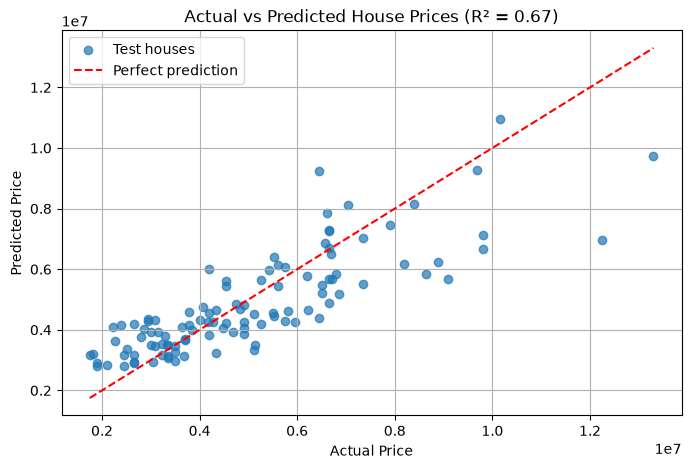

In [8]:
plt.figure(figsize=(8,5))
plt.scatter(y_test, y_pred, alpha=.7, label="Test houses")

# Perfect-prediction line: predicted = actual
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(lims, lims, "r--", label="Perfect prediction")

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title(f"Actual vs Predicted House Prices (R² = {r2:.2f})")
plt.legend()
plt.grid(True)
plt.show()

In [6]:
new_house=pd.DataFrame([{c:float(X[c].median()) for c in features}]); prediction=model.predict(new_house)[0]; display(new_house); print(f"Predicted House Price: {prediction:,.2f}")

,area,bedrooms,bathrooms,stories,parking,mainroad_yes,guestroom_yes,basement_yes,hotwaterheating_yes,airconditioning_yes,prefarea_yes,furnishingstatus_semi-furnished,furnishingstatus_unfurnished
0,4600.0,3.0,1.0,2.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Predicted House Price: 3,917,129.43


In [9]:
# ---------- Predict the price of a new house ----------
def ask_number(prompt, kind=float, minimum=0):
    """Keep asking until the user types a valid number."""
    while True:
        try:
            value = kind(input(prompt))
            if value < minimum:
                print(f"  Please enter a value of at least {minimum}.")
                continue
            return value
        except ValueError:
            print("  Please enter a valid number.")

def ask_yes_no(prompt):
    """Return 1 for yes, 0 for no."""
    while True:
        answer = input(prompt + " (yes/no): ").strip().lower()
        if answer in ("yes", "y"):
            return 1
        if answer in ("no", "n"):
            return 0
        print("  Please type yes or no.")

print("Enter the details of the house:\n")

# Start with every column set to 0, then fill in the user's answers
new_house = pd.DataFrame([{c: 0 for c in features}])

new_house["area"]      = ask_number("Area (sq ft): ", float, 1)
new_house["bedrooms"]  = ask_number("Bedrooms: ", int, 1)
new_house["bathrooms"] = ask_number("Bathrooms: ", int, 1)
new_house["stories"]   = ask_number("Stories: ", int, 1)
new_house["parking"]   = ask_number("Parking spaces: ", int, 0)

new_house["mainroad_yes"]        = ask_yes_no("On a main road?")
new_house["guestroom_yes"]       = ask_yes_no("Has a guest room?")
new_house["basement_yes"]        = ask_yes_no("Has a basement?")
new_house["hotwaterheating_yes"] = ask_yes_no("Has hot water heating?")
new_house["airconditioning_yes"] = ask_yes_no("Has air conditioning?")
new_house["prefarea_yes"]        = ask_yes_no("In a preferred area?")

furnishing = ""
while furnishing not in ("furnished", "semi-furnished", "unfurnished"):
    furnishing = input("Furnishing (furnished / semi-furnished / unfurnished): ").strip().lower()
# 'furnished' is the base case, so both columns stay 0 for it
if furnishing == "semi-furnished":
    new_house["furnishingstatus_semi-furnished"] = 1
elif furnishing == "unfurnished":
    new_house["furnishingstatus_unfurnished"] = 1

prediction = model.predict(new_house[features])[0]
print(f"\nPredicted House Price: {prediction:,.2f}")

Enter the details of the house:


Predicted House Price: 5,540,469.37


## Conclusion

The Linear Regression model learns the relationship between property features and historical prices and predicts the price of a new house. This provides a simple real-world application of supervised machine learning for real-estate price estimation.